In [1]:
import os, glob
import matplotlib.pyplot as plt
import scipy.io
import numpy as np
import pandas as pd

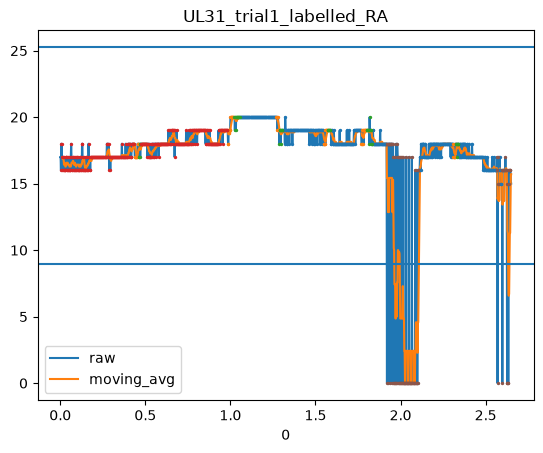

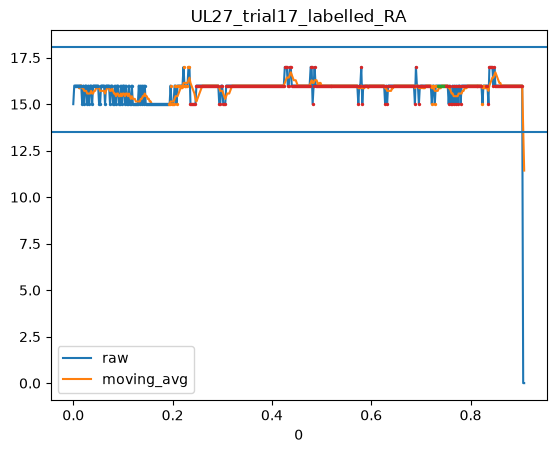

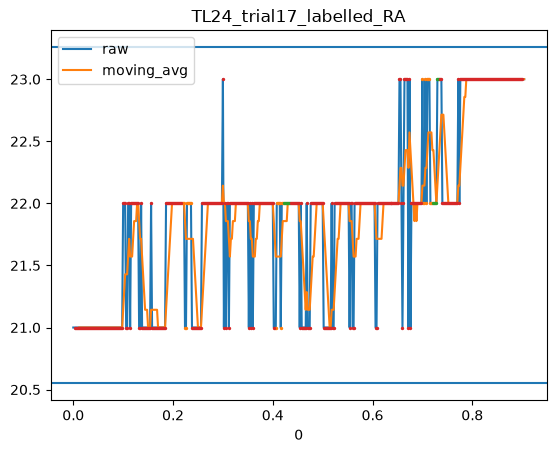

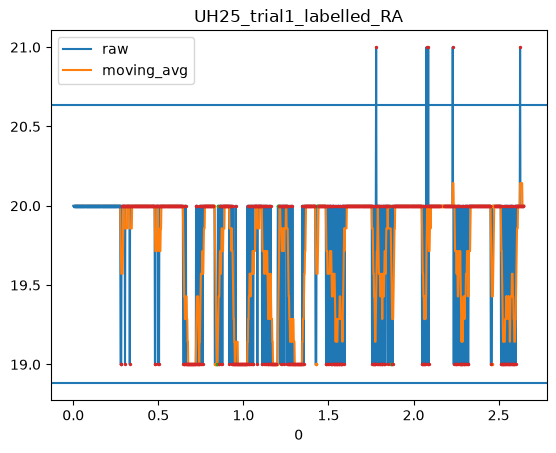

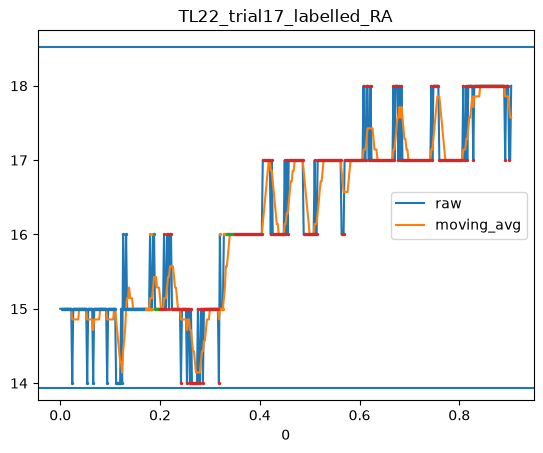

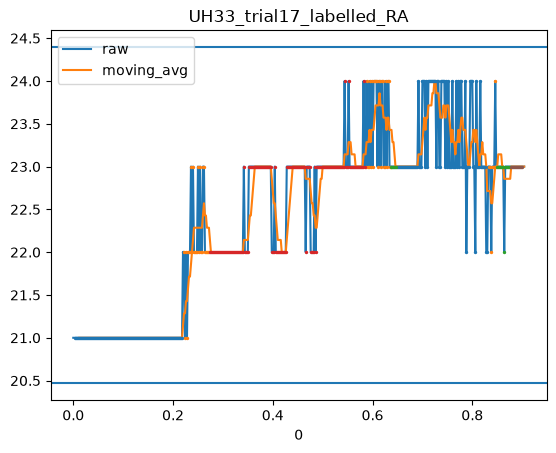

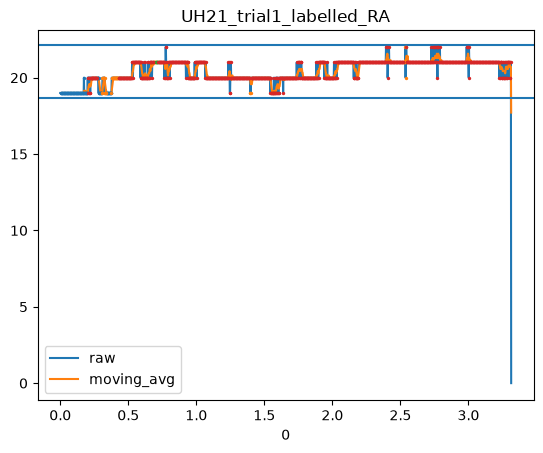

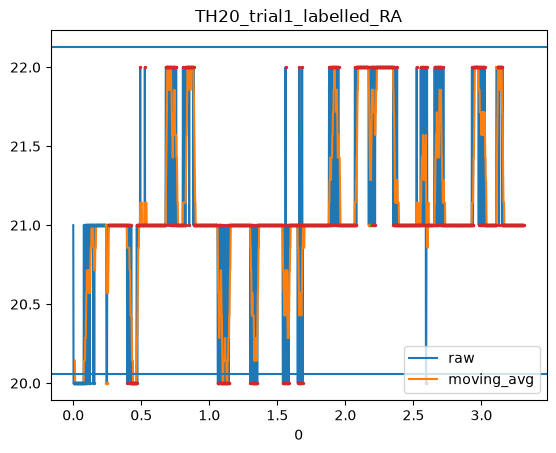

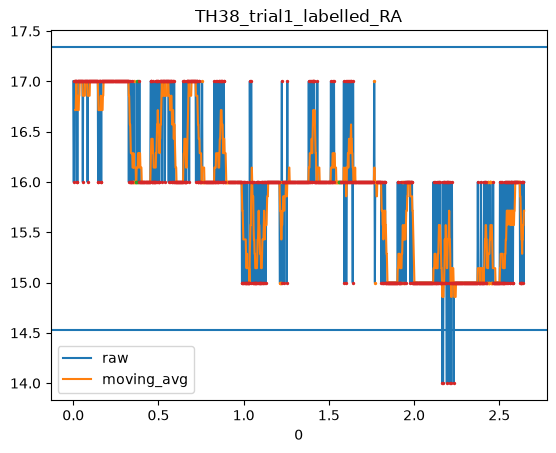

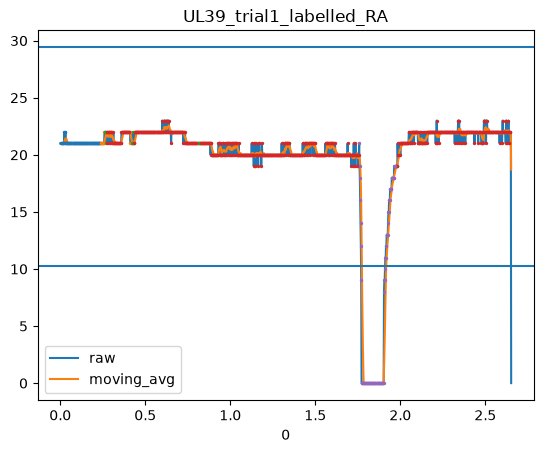

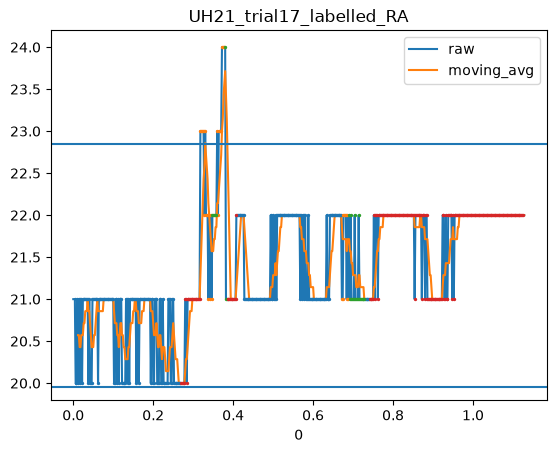

In [24]:
dirs_datas_RA = glob.glob(os.path.join(r"./EyeMovementDetectorEvaluation/annotated_data/data used in the article/dots", "*_labelled_RA.mat"))

for dir_datas_RA in dirs_datas_RA:
    mat_data = scipy.io.loadmat(dir_datas_RA)

    sampFreq = mat_data["ETdata"]["sampFreq"][0][0][0][0]
    viewDist = mat_data["ETdata"]["viewDist"][0][0][0][0]
    screenDim = mat_data["ETdata"]["screenDim"][0][0][0]
    screenRes = mat_data["ETdata"]["screenRes"][0][0][0]
    x_center, y_center = (screenRes-1)/2

    df_data = pd.DataFrame(mat_data["ETdata"]["pos"][0][0])
    df_data[0] = (1/sampFreq)*df_data.index 
    df_data[5] = df_data[5].astype('int64')

    df_data["pos_x"] = df_data[3] - x_center
    df_data["pos_y"] = df_data[4] - y_center

    moving_average_window = 7
    df_data["pupil_x_moving_avg"] = df_data[1].rolling(moving_average_window).mean()
    df_data["pupil_y_moving_avg"] = df_data[2].rolling(moving_average_window).mean() 
    

    fig = plt.figure()
    ax = fig.add_subplot(1, 1, 1)

    df_data.plot(x=0, y=2, label="raw", ax=ax)
    df_data.plot(x=0, y="pupil_y_moving_avg", label="moving_avg", ax=ax)

    puli_x_mean = df_data[1].mean()
    puli_x_std = df_data[1].std()
    puli_y_mean = df_data[2].mean()
    puli_y_std = df_data[2].std()

    l_label = np.array([1,2,3,4,5,6])
    d_label = {
        1: "Fixation",
        2: "Saccade",
        3: "Post-saccadic oscillation",
        4: "mooth pursuit",
        5: "Blink",
        6: "Undefined",
        }
    for i_label in l_label:
        df_data_slice = df_data.iloc[2:-2][df_data.iloc[2:-2][5]==i_label].copy()
        plt.scatter(df_data_slice[0], df_data_slice[2], label=d_label[i_label], s=2, zorder=5)

    sigma_ratio = 2
    ax.axhline(puli_y_mean+puli_y_std*sigma_ratio)
    ax.axhline(puli_y_mean-puli_y_std*sigma_ratio)
    ax.set_title(os.path.basename(dir_datas_RA).replace(".mat", ""))
    plt.show()